# Student Academic Performance Analysis using Regression Models

## 1. Introduction
  
    Student academic performance is a key indicator of learning outcomes and educational effectiveness.
    Understanding the factors that influence student performance is essential for improving teaching strategies and providing timely academic interventions.

    This project focuses on analyzing academic and behavioral factors that affect student performance and building regression-based models to predict final grades.
    Unlike tutorial-based prediction tasks, this study emphasizes interpretability, statistical analysis, and comparative modeling to derive meaningful educational insights.
 
  ### Problem Statement

    The objective of this study is to analyze the impact of academic history and behavioral factors on student performance and to develop regression models capable of predicting final examination grades.
    The study also aims to identify the most influential factors contributing to academic success through statistical and machine learning techniques.

   
## 2. Dataset Description
      The dataset used in this study is the Student Performance Dataset obtained from the UCI Machine Learning Repository.
      It contains academic, demographic, and behavioral attributes of secondary school students.

      In this analysis, the student-mat.csv file is used, which includes records of students enrolled in mathematics courses.
      Key attributes include study time, number of past failures, attendance (absences), previous period grades (G1 and G2), and the final grade (G3), which serves as the target variable.
  ### Research Objectives

  - To explore relationships between academic and behavioral factors and student performance
  - To build and evaluate regression-based prediction models
  - To compare different regression techniques for academic performance prediction
  - To interpret model outcomes for actionable educational insights
  
  ### Scope of the Study

  This study focuses on academic and behavioral attributes available in the dataset and does not include psychological or socio-economic factors beyond those provided.


## 3. Exploratory Data Analysis (EDA)

## 4. Feature Engineering

## 5. Model Building

## 6. Model Evaluation

## 7. Model Comparison

## 8. Interpretation and Insights

## 9. Conclusion and Future Work


In [1]:
# TITLE 
# “Analyzing the Impact of Behavioral and Academic Factors on Student Performance using Regression and Feature Analysis”
# "Focus not only on prediction, but on:

#"Factor analysis,Interpretabilit,Educational insights"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

sns.set(style="whitegrid")


In [3]:
data = pd.read_csv("student-mat.csv", sep=';')

data.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# -------------------------------
# Feature Engineering
# -------------------------------

# Average of first two period grades
data['avg_prev_grade'] = (data['G1'] + data['G2']) / 2

# Binary feature: high absenteeism
data['high_absence'] = (data['absences'] > 10).astype(int)

data[['G1','G2','avg_prev_grade','absences','high_absence']].head()


,G1,G2,avg_prev_grade,absences,high_absence
0,5,6,5.5,6,0
1,5,5,5.0,4,0
2,7,8,7.5,10,0
3,15,14,14.5,2,0
4,6,10,8.0,4,0


In [5]:
data.shape
data.describe()


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,avg_prev_grade,high_absence
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190,10.811392,0.167089
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443,3.407479,0.373528
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000,2.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000,8.500000,0.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000,11.000000,0.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000,13.000000,0.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000,19.000000,1.000000


The dataset contains academic and behavioral records of students.
Descriptive statistics indicate that final grades (G3) vary across a wide range, suggesting diversity in academic performance among students.


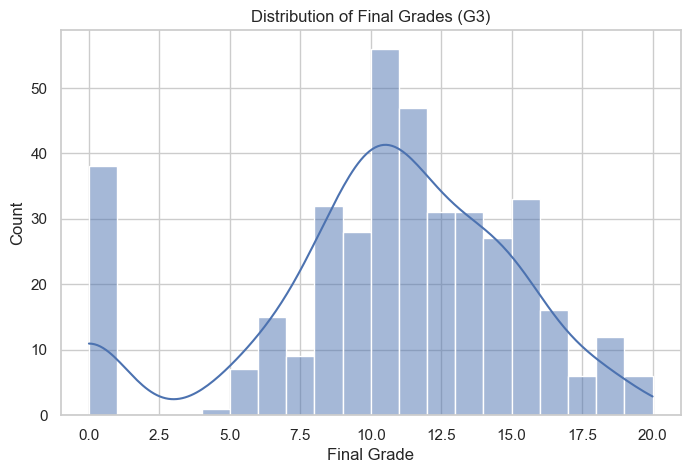

In [6]:
plt.figure(figsize=(8,5))
sns.histplot(data['G3'], bins=20, kde=True)
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Count")
plt.show()


The distribution of final grades shows a roughly bell-shaped pattern with most students scoring in the mid-range.
This indicates that extreme high or low performances are less frequent, which is suitable for regression-based modeling.
The distribution of final grades shows a roughly bell-shaped pattern with most students scoring in the mid-range.
This indicates that extreme high or low performances are less frequent, which is suitable for regression-based modeling.


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 35 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   school          395 non-null    object 
 1   sex             395 non-null    object 
 2   age             395 non-null    int64  
 3   address         395 non-null    object 
 4   famsize         395 non-null    object 
 5   Pstatus         395 non-null    object 
 6   Medu            395 non-null    int64  
 7   Fedu            395 non-null    int64  
 8   Mjob            395 non-null    object 
 9   Fjob            395 non-null    object 
 10  reason          395 non-null    object 
 11  guardian        395 non-null    object 
 12  traveltime      395 non-null    int64  
 13  studytime       395 non-null    int64  
 14  failures        395 non-null    int64  
 15  schoolsup       395 non-null    object 
 16  famsup          395 non-null    object 
 17  paid            395 non-null    obj

In [8]:
data[['G1','G2','avg_prev_grade','absences','high_absence']].head()


,G1,G2,avg_prev_grade,absences,high_absence
0,5,6,5.5,6,0
1,5,5,5.0,4,0
2,7,8,7.5,10,0
3,15,14,14.5,2,0
4,6,10,8.0,4,0


Correlation with Final Grade (G3):
G3                1.000000
G2                0.904868
avg_prev_grade    0.889792
G1                0.801468
Medu              0.217147
Fedu              0.152457
studytime         0.097820
famrel            0.051363
absences          0.034247
freetime          0.011307
high_absence     -0.025810
Walc             -0.051939
Dalc             -0.054660
health           -0.061335
traveltime       -0.117142
goout            -0.132791
age              -0.161579
failures         -0.360415
Name: G3, dtype: float64


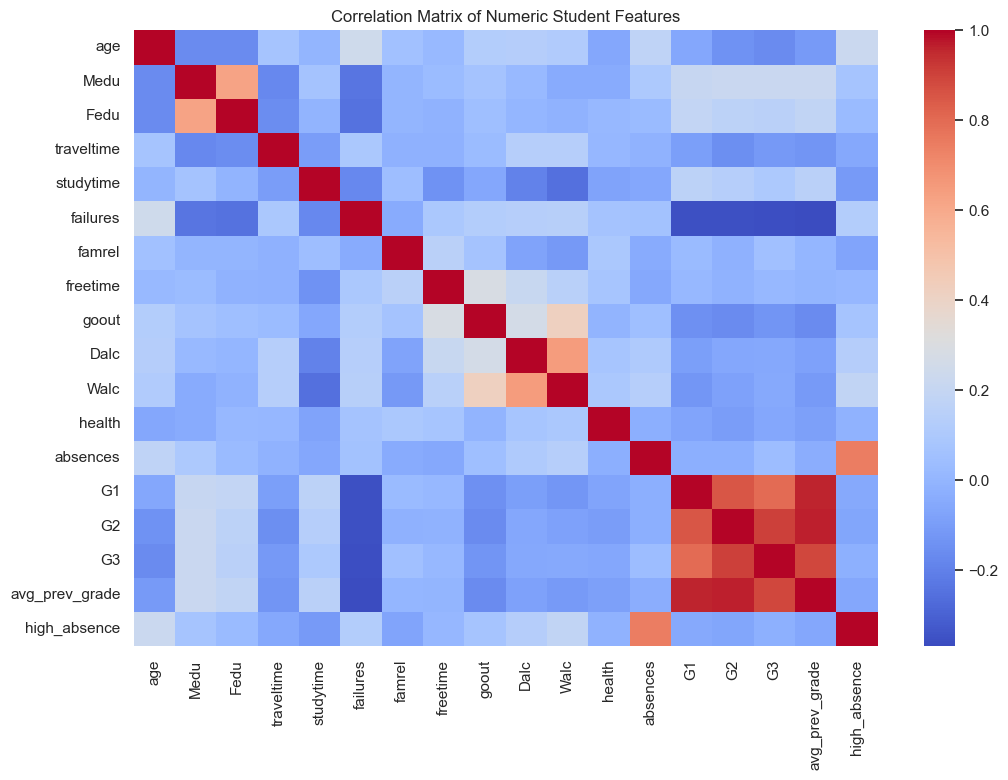

In [9]:
# Select only numeric columns
numeric_data = data.select_dtypes(include=['int64', 'float64'])

# Correlation with final grade
grade_corr = numeric_data.corr()['G3'].sort_values(ascending=False)
print("Correlation with Final Grade (G3):")
print(grade_corr)

# Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(numeric_data.corr(), cmap='coolwarm', annot=False)
plt.title("Correlation Matrix of Numeric Student Features")
plt.show()


The correlation matrix reveals strong positive relationships between previous grades (G1, G2) and the final grade (G3).
Absences show a negative correlation with final performance, indicating that higher absenteeism is associated with lower academic outcomes.


In [10]:
grade_corr = numeric_data.corr()['G3'].sort_values(ascending=False)
grade_corr

G3                1.000000
G2                0.904868
avg_prev_grade    0.889792
G1                0.801468
Medu              0.217147
Fedu              0.152457
studytime         0.097820
famrel            0.051363
absences          0.034247
freetime          0.011307
high_absence     -0.025810
Walc             -0.051939
Dalc             -0.054660
health           -0.061335
traveltime       -0.117142
goout            -0.132791
age              -0.161579
failures         -0.360415
Name: G3, dtype: float64

Previous academic performance (G1 and G2) exhibits the highest correlation with final grades.
Behavioral factors such as absences also influence performance, though to a lesser extent.


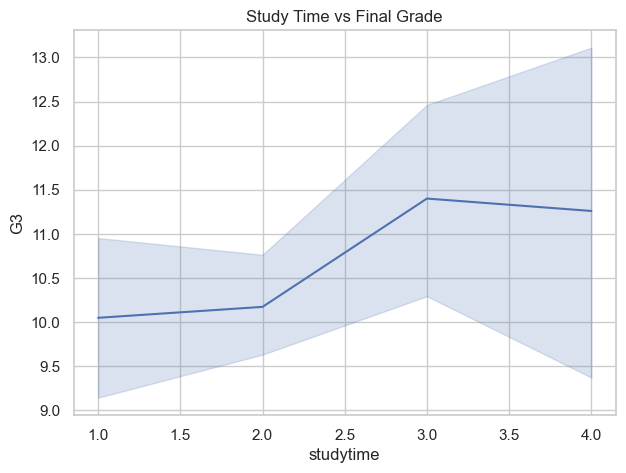

In [11]:
plt.figure(figsize=(7,5))
sns.lineplot(x='studytime', y='G3', data=data)
plt.title("Study Time vs Final Grade")
plt.show()

The scatter plot suggests a positive trend between study time and final grades.
Students who dedicate more time to studying tend to achieve better academic results.


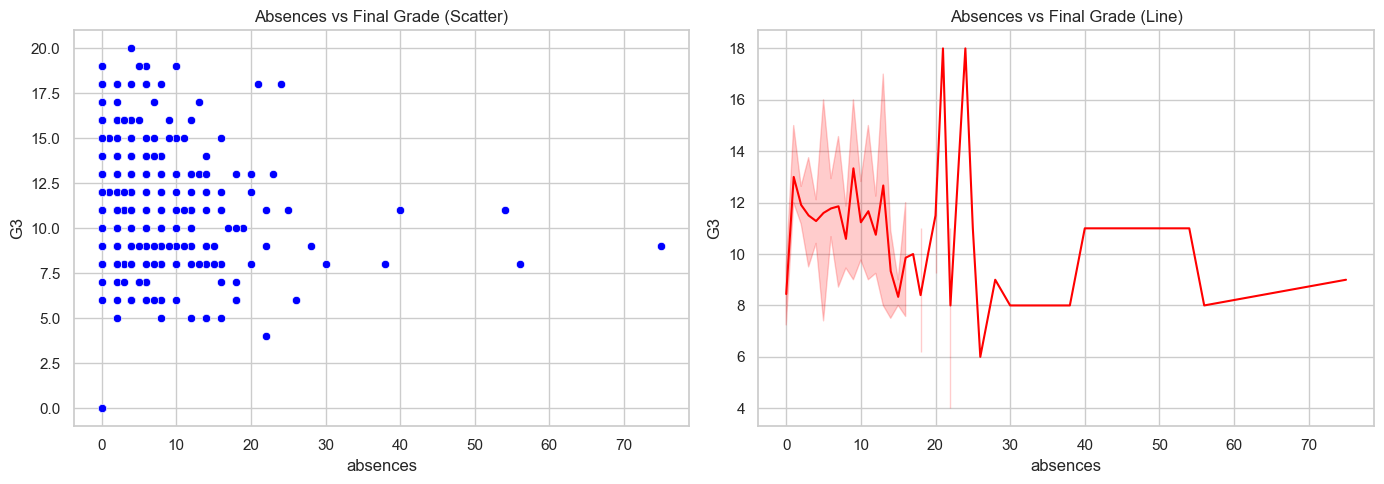

In [12]:

# Create a figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Scatter plot on the first subplot
sns.scatterplot(x='absences', y='G3', data=data, ax=axes[0], color='blue')
axes[0].set_title("Absences vs Final Grade (Scatter)")

# Line plot on the second subplot
sns.lineplot(x='absences', y='G3', data=data, ax=axes[1], color='red')
axes[1].set_title("Absences vs Final Grade (Line)")

plt.tight_layout()
plt.show()


In [13]:
features = ['studytime', 'failures', 'absences', 'G1', 'G2']
X = data[features]
y = data['G3']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [14]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


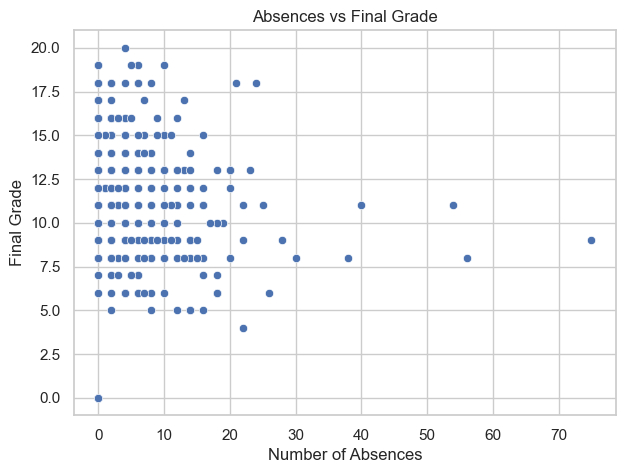

In [15]:
plt.figure(figsize=(7,5))
sns.scatterplot(x='absences', y='G3', data=data)
plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()


A negative relationship is observed between absences and final grades.
As the number of absences increases, student performance generally declines, highlighting the importance of regular attendance.


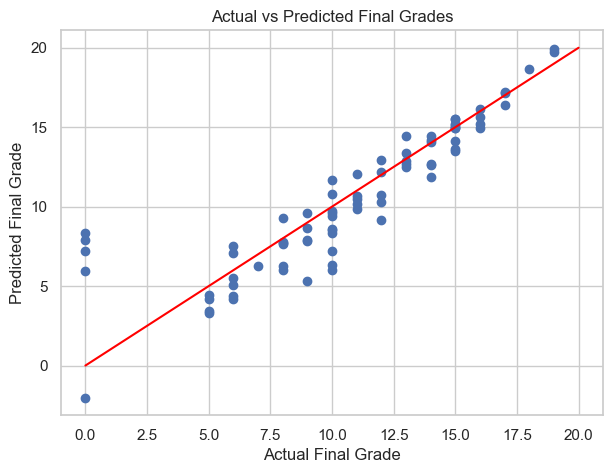

In [16]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred)
plt.plot([0,20], [0,20], color='red')  # perfect prediction line
plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Final Grades")
plt.show()


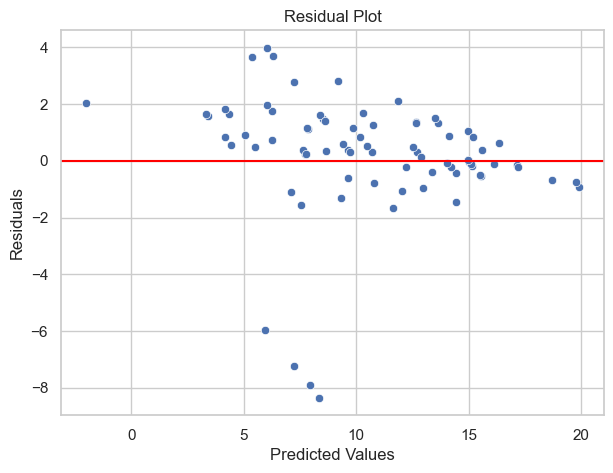

In [17]:
residuals = y_test - y_pred

plt.figure(figsize=(7,5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


In [18]:
print("Linear Regression Performance:")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


Linear Regression Performance:
MAE: 1.3394159082670933
MSE: 4.466503212015606
R2 Score: 0.7821754247320555


In [19]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

ridge_pred = ridge.predict(X_test_scaled)

print("\nRidge Regression Performance:")
print("R2 Score:", r2_score(y_test, ridge_pred))



Ridge Regression Performance:
R2 Score: 0.7822739235199543


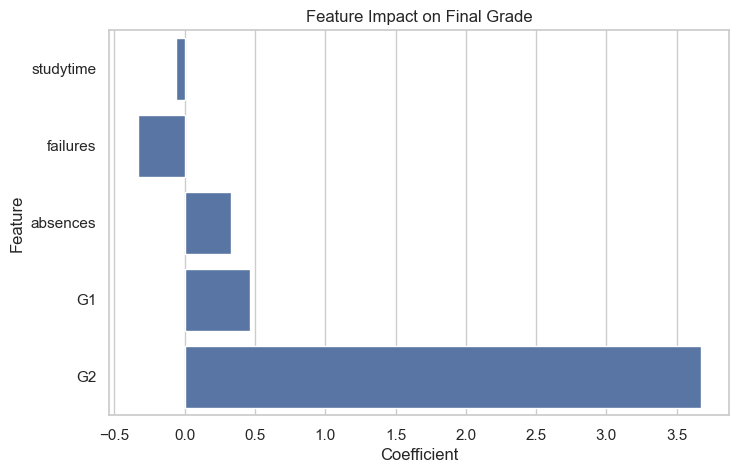

In [20]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

plt.figure(figsize=(8,5))
sns.barplot(x="Coefficient", y="Feature", data=coefficients)
plt.title("Feature Impact on Final Grade")
plt.show()


In [21]:
from sklearn.linear_model import Lasso, ElasticNet

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Elastic Net": ElasticNet(alpha=0.01, l1_ratio=0.5)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    results.append([
        name,
        mean_absolute_error(y_test, preds),
        mean_squared_error(y_test, preds),
        r2_score(y_test, preds)
    ])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "R2 Score"])
results_df


,Model,MAE,MSE,R2 Score
0,Linear Regression,1.339416,4.466503,0.782175
1,Ridge Regression,1.339137,4.464483,0.782274
2,Lasso Regression,1.331925,4.463105,0.782341
3,Elastic Net,1.335266,4.461667,0.782411


In [22]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(LinearRegression(), X_train_scaled, y_train, cv=5, scoring='r2')
print("Cross Validation R2 Scores:", cv_scores)
print("Mean CV R2:", cv_scores.mean())


Cross Validation R2 Scores: [0.83027814 0.8689634  0.85851996 0.80853625 0.7981226 ]
Mean CV R2: 0.8328840719523963


This study analyzed student academic performance using machine learning techniques. Exploratory data analysis revealed that previous academic scores (G1 and G2) have the strongest positive correlation with final grade (G3), while absences show a negative relationship.

Among the tested models, Linear Regression and Ridge Regression achieved strong R² scores, indicating good predictive capability.

The results confirm that academic consistency is the most significant predictor of student performance. Future work may include advanced ensemble models or feature expansion for improved accuracy.